&nbsp;
# <div align=center><font color=green> <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> : Clustering Methods &  GMM & Nonparametric Methods & Ensemble Learning & Model Selection and Evaluation</font></div>
<!-- # <div align=center> Part II </div> -->
## <div align=center>Zhexian Yang & Ziping Zhao</div>

**<div align=center> School of Information Science and Technology </div>**
**<div align=center>ShanghaiTech University, Shanghai, China</div>**

**<div align=center><font size="7">CS182: Introduction to Machine Learning<font/></div>**
    
**<div align=center><font size="7">http://cs182.sist.shanghaitech.edu.cn<font/></div>**

### <div align=center><font color=green> Sec. 2.3, Sec. 2.1, Sec. 2.8, Sec. 1.11 & Sec. 3 of  <span style="background-color: #e6f7ff; padding: 2px; color: green; font-family: monospace;">Scikit-learn</span> </font></div>

## Learning Objectives

- Introduction to Clustering Algorithm in `scikit-learn`.

- Introduction to Gaussian Mixture Models in `scikit-learn`.

- Introduction to Nonparametric Methods in `scikit-learn`.

- Introduction to Ensemble Learning in `scikit-learn`.

- Introduction to Model Selection and Evaluation in `scikit-learn`.

# <div align=Left>Clustering Methods</div>
<br />

## Clustering Methods in `sklearn.cluster`

- Clustering of unlabeled data can be performed with the module `sklearn.cluster`.
<br />

- All the methods accept standard data matrices of shape (n_samples, n_features). 

## Clustering Methods 

- k-Means
<br />

- Hierarchical clustering 

## k-Means
- The k-Means algorithm clusters data by trying to separate samples in k groups.

- This algorithm requires the number of clusters to be specified. 

- It scales well to large numbers of samples and has been used across a large range of application areas in many different fields.


## k-Means
- The k-means algorithm divides a set of n samples X into k disjoint clusters C, each described by the mean $\mu_j$ of the samples in the cluster. The means are commonly called the cluster “centroids”; note that they are not, in general, points from X, although they live in the same space.

- The k-means algorithm aims to choose centroids that minimise the inertia, or within-cluster sum-of-squares criterion:

$$\sum_{i=0}^{n}\min_{\mu_j \in C}(||x_i - \mu_j||^2)$$


## k-Means

In basic terms, the algorithm has three steps.

- The first step chooses the initial centroids, with the most basic method being to choose k samples from the dataset X. 

- After initialization, K-means consists of looping between the two other steps. The first step assigns each sample to its nearest centroid. 

- The second step creates new centroids by taking the mean value of all of the samples assigned to each previous centroid. It repeats until the centroids do not move significantly.

## k-Means

`class sklearn.cluster.KMeans(n_clusters=8, *, init='k-means++', n_init='auto', max_iter=300, tol=0.0001, verbose=0, random_state=None, copy_x=True, algorithm='lloyd')`

- n_clusters: The number of clusters.

- init: Method for initialization

- n_init: Number of times the k-means algorithm is run with different centroid seeds.

- max_iter: Maximum number of iterations of the k-means algorithm for a single run.

- tol: Relative tolerance with regards to Frobenius norm of the difference in the cluster centers of two consecutive iterations to declare convergence.

- verbose: Verbosity mode.

- random_state: Determines random number generation for centroid initialization. 

- copy_x: When pre-computing distances it is more numerically accurate to center the data first. If copy_x is True (default), then the original data is not modified. 

- algorithm: K-means algorithm to use. 

In [1]:
from sklearn.cluster import KMeans
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0],
              [10, 2], [10, 4], [10, 0]])
kmeans = KMeans(n_clusters=2, random_state=0, n_init="auto").fit(X)
kmeans.labels_


array([1, 1, 1, 0, 0, 0], dtype=int32)

In [2]:
kmeans.predict([[0, 0], [12, 3]])

array([1, 0], dtype=int32)

In [3]:
kmeans.cluster_centers_

array([[10.,  2.],
       [ 1.,  2.]])

## Hierarchical clustering
- Hierarchical clustering is a general family of clustering algorithms that build nested clusters by merging or splitting them successively.

- This hierarchy of clusters is represented as a tree (or dendrogram). 

- The root of the tree is the unique cluster that gathers all the samples, the leaves being the clusters with only one sample. 

## Hierarchical clustering

The `AgglomerativeClustering` object performs a hierarchical clustering using a bottom up approach: each observation starts in its own cluster, and clusters are successively merged together. 

- `Ward` minimizes the sum of squared differences within all clusters. It is a variance-minimizing approach and in this sense is similar to the k-means objective function but tackled with an agglomerative hierarchical approach.

- `Maximum` or `complete linkage` minimizes the maximum distance between observations of pairs of clusters.

- `Average linkage` minimizes the average of the distances between all observations of pairs of clusters.

- `Single linkage` minimizes the distance between the closest observations of pairs of clusters.

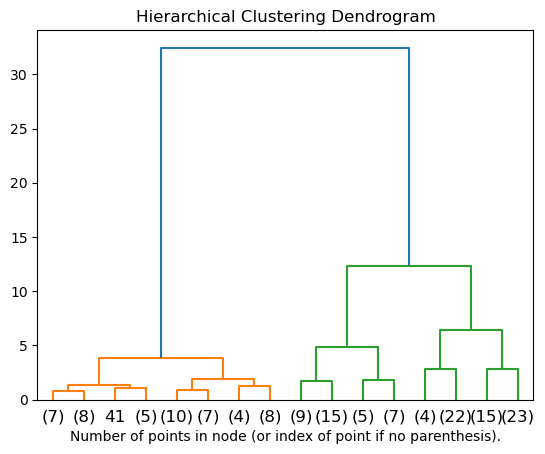

In [4]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram

from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)


iris = load_iris()
X = iris.data

model = AgglomerativeClustering(distance_threshold=0, n_clusters=None)

model = model.fit(X)
plt.title("Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(model, truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

## Gaussian mixture models (GMM)

## <div align=Left> Gaussian mixture models in `sklearn.mixture`</div>
- `sklearn.mixture` is a package which enables one to learn Gaussian Mixture Models (diagonal, spherical, tied and full covariance matrices supported), sample them, and estimate them from data. 

- A Gaussian mixture model is a probabilistic model that assumes all the data points are generated from a mixture of a finite number of Gaussian distributions with unknown parameters.

## <div align=Left> Gaussian mixture models in `sklearn.mixture`</div>
- The `GaussianMixture` object implements the expectation-maximization (EM) algorithm for fitting mixture-of-Gaussian models. 

- A `GaussianMixture.fit` method is provided that learns a Gaussian Mixture Model from train data. 

- Given test data, it can assign to each sample the Gaussian it most probably belongs to using the `GaussianMixture.predict` method.

## Gaussian mixture models

`class sklearn.mixture.GaussianMixture(n_components=1, *, covariance_type='full', tol=0.001, reg_covar=1e-06, max_iter=100, n_init=1, init_params='kmeans', weights_init=None, means_init=None, precisions_init=None, random_state=None, warm_start=False, verbose=0, verbose_interval=10)`

- n_components: The number of mixture components.

- covariance_type: String describing the type of covariance parameters to use. Must be one of: {‘full’, ‘tied’, ‘diag’, ‘spherical’}, default=’full’

- tol: The convergence threshold. EM iterations will stop when the lower bound average gain is below this threshold.

- reg_covar: Non-negative regularization added to the diagonal of covariance. 

- max_iter: The number of EM iterations to perform.

- n_init: The number of initializations to perform. 

- init_params: The method used to initialize the weights, the means and the precisions. String must be one of: {‘kmeans’, ‘k-means++’, ‘random’, ‘random_from_data’}, default=’kmeans’

- weights_init: The user-provided initial weights. 

- means_init: The user-provided initial means.

- precisions_init: The user-provided initial precisions (inverse of the covariance matrices). 

- random_state: Controls the random seed given to the method chosen to initialize the parameters.

- warm_start: If ‘warm_start’ is True, the solution of the last fitting is used as initialization for the next call of fit().

- verbose : Enable verbose output. 

- verbose_interval: Number of iteration done before the next print.

In [5]:
import numpy as np
from sklearn.mixture import GaussianMixture
X = np.array([[1, 2], [1, 4], [1, 0], [10, 2], [10, 4], [10, 0]])
gm = GaussianMixture(n_components=2, random_state=0).fit(X)


In [6]:
gm.predict(X)

array([1, 1, 1, 0, 0, 0])

In [7]:
gm.means_

array([[10.,  2.],
       [ 1.,  2.]])

In [8]:
gm.predict([[0, 0], [12, 3]])

array([1, 0])

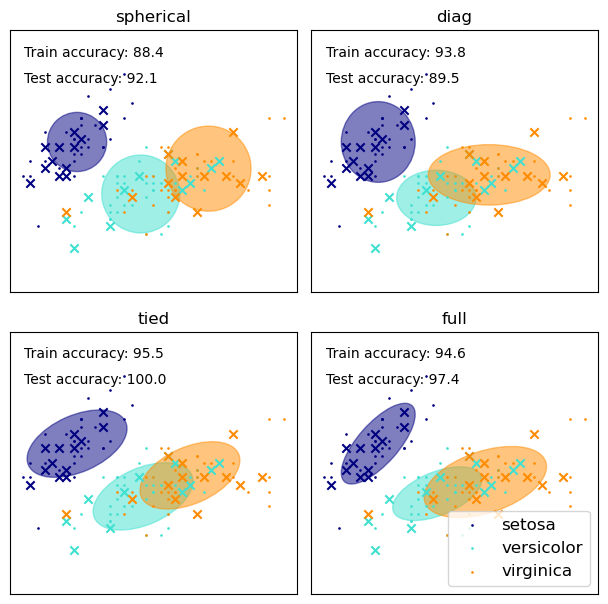

In [9]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold

colors = ["navy", "turquoise", "darkorange"]


def make_ellipses(gmm, ax):
    for n, color in enumerate(colors):
        if gmm.covariance_type == "full":
            covariances = gmm.covariances_[n][:2, :2]
        elif gmm.covariance_type == "tied":
            covariances = gmm.covariances_[:2, :2]
        elif gmm.covariance_type == "diag":
            covariances = np.diag(gmm.covariances_[n][:2])
        elif gmm.covariance_type == "spherical":
            covariances = np.eye(gmm.means_.shape[1]) * gmm.covariances_[n]
        v, w = np.linalg.eigh(covariances)
        u = w[0] / np.linalg.norm(w[0])
        angle = np.arctan2(u[1], u[0])
        angle = 180 * angle / np.pi  # convert to degrees
        v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
        ell = mpl.patches.Ellipse(
            gmm.means_[n, :2], v[0], v[1], angle=180 + angle, color=color
        )
        ell.set_clip_box(ax.bbox)
        ell.set_alpha(0.5)
        ax.add_artist(ell)
        ax.set_aspect("equal", "datalim")


iris = datasets.load_iris()

# Break up the dataset into non-overlapping training (75%) and testing
# (25%) sets.
skf = StratifiedKFold(n_splits=4)
# Only take the first fold.
train_index, test_index = next(iter(skf.split(iris.data, iris.target)))


X_train = iris.data[train_index]
y_train = iris.target[train_index]
X_test = iris.data[test_index]
y_test = iris.target[test_index]

n_classes = len(np.unique(y_train))

# Try GMMs using different types of covariances.
estimators = {
    cov_type: GaussianMixture(
        n_components=n_classes, covariance_type=cov_type, max_iter=20, random_state=0
    )
    for cov_type in ["spherical", "diag", "tied", "full"]
}

n_estimators = len(estimators)

plt.figure(figsize=(3 * n_estimators // 2, 6))
plt.subplots_adjust(
    bottom=0.01, top=0.95, hspace=0.15, wspace=0.05, left=0.01, right=0.99
)


for index, (name, estimator) in enumerate(estimators.items()):
    # Since we have class labels for the training data, we can
    # initialize the GMM parameters in a supervised manner.
    estimator.means_init = np.array(
        [X_train[y_train == i].mean(axis=0) for i in range(n_classes)]
    )

    # Train the other parameters using the EM algorithm.
    estimator.fit(X_train)

    h = plt.subplot(2, n_estimators // 2, index + 1)
    make_ellipses(estimator, h)

    for n, color in enumerate(colors):
        data = iris.data[iris.target == n]
        plt.scatter(
            data[:, 0], data[:, 1], s=0.8, color=color, label=iris.target_names[n]
        )
    # Plot the test data with crosses
    for n, color in enumerate(colors):
        data = X_test[y_test == n]
        plt.scatter(data[:, 0], data[:, 1], marker="x", color=color)

    y_train_pred = estimator.predict(X_train)
    train_accuracy = np.mean(y_train_pred.ravel() == y_train.ravel()) * 100
    plt.text(0.05, 0.9, "Train accuracy: %.1f" % train_accuracy, transform=h.transAxes)

    y_test_pred = estimator.predict(X_test)
    test_accuracy = np.mean(y_test_pred.ravel() == y_test.ravel()) * 100
    plt.text(0.05, 0.8, "Test accuracy: %.1f" % test_accuracy, transform=h.transAxes)

    plt.xticks(())
    plt.yticks(())
    plt.title(name)

plt.legend(scatterpoints=1, loc="lower right", prop=dict(size=12))


plt.show()

## Nonparametric Methods

## Density Estimation

- Density Estimation: Histograms

- Kernel Density Estimation

## Density Estimation: Histograms

A histogram is a simple visualization of data where bins are defined, and the number of data points within each bin is tallied. An example of a histogram can be seen in the upper-left panel of the following figure:


![本地路径](sphx_glr_plot_kde_1d_001.png) <!-- 此路径表示图片和MD文件，处于同一目录 -->



A major problem with histograms, however, is that the choice of binning can have a disproportionate effect on the resulting visualization. Consider the upper-right panel of the above figure. It shows a histogram over the same data, with the bins shifted right. The results of the two visualizations look entirely different, and might lead to different interpretations of the data.

## Kernel Density Estimation

Kernel density estimation in scikit-learn is implemented in the `KernelDensity` estimator, which uses the Ball Tree or KD Tree for efficient queries (see Nearest Neighbors for a discussion of these). 

In the following figure, 100 points are drawn from a bimodal distribution, and the kernel density estimates are shown for three choices of kernels:

![本地路径](sphx_glr_plot_kde_1d_003.png) <!-- 此路径表示图片和MD文件，处于同一目录 -->

It’s clear how the kernel shape affects the smoothness of the resulting distribution. The scikit-learn kernel density estimator can be used as follows:

In [10]:
from sklearn.neighbors import KernelDensity
import numpy as np
X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])
kde = KernelDensity(kernel='gaussian', bandwidth=0.2).fit(X)

Here we have used `kernel='gaussian'`, as seen above. Mathematically, a kernel is a positive function $K(x;h)$ which is controlled by the bandwidth parameter $h$. Given this kernel form, the density estimate at a point $y$ within a group of points $x_i; i=1\cdots N$ is given by:

$$\rho_K(y) = \sum_{i=1}^{N} K(y - x_i; h)$$
The bandwidth here acts as a smoothing parameter, controlling the tradeoff between bias and variance in the result. A large bandwidth leads to a very smooth (i.e. high-bias) density distribution. A small bandwidth leads to an unsmooth (i.e. high-variance) density distribution.

The parameter `bandwidth` controls this smoothing. 

##  Ensemble Learning

## Ensemble Learning

- Bagging meta-estimator (Voting Classifier and Voting Regressor)

- AdaBoost

## Bagging meta-estimator
In ensemble algorithms, bagging methods form a class of algorithms which build several instances of a black-box estimator on random subsets of the original training set and then aggregate their individual predictions to form a final prediction. 

## Bagging meta-estimator
In scikit-learn, bagging methods are offered as a unified `BaggingClassifier` meta-estimator (resp. `BaggingRegressor`), taking as input a user-specified estimator along with parameters specifying the strategy to draw random subsets.

- `max_samples` and `max_features` control the size of the subsets (in terms of samples and features)

- `bootstrap` and `bootstrap_features` control whether samples and features are drawn with or without replacement

- When using a subset of the available samples the generalization accuracy can be estimated with the out-of-bag samples by setting `oob_score=True`.

As an example, the snippet below illustrates how to instantiate a bagging ensemble of `KNeighborsClassifier` estimators, each built on random subsets of 50% of the samples and 50% of the features.

In [11]:
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
bagging = BaggingClassifier(KNeighborsClassifier(),
                            max_samples=0.5, max_features=0.5)

## Voting Classifier
The idea behind the `VotingClassifier` is to combine conceptually different machine learning classifiers and use a majority vote or the average predicted probabilities (soft vote) to predict the class labels. 

- Majority Class Labels (Majority/Hard Voting)

- Weighted Average Probabilities (Soft Voting)

## Majority Class Labels (Majority/Hard Voting)

In majority voting, the predicted class label for a particular sample is the class label that represents the majority (mode) of the class labels predicted by each individual classifier.

E.g., if the prediction for a given sample is

- classifier 1 -> class 1

- classifier 2 -> class 1

- classifier 3 -> class 2

the VotingClassifier (with voting='hard') would classify the sample as “class 1” based on the majority class label.

The following example shows how to fit the majority rule classifier:

In [12]:
from sklearn import datasets
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier

iris = datasets.load_iris()
X, y = iris.data[:, 1:3], iris.target

clf1 = LogisticRegression(random_state=1)
clf2 = RandomForestClassifier(n_estimators=50, random_state=1)
clf3 = GaussianNB()

eclf = VotingClassifier(
    estimators=[('lr', clf1), ('rf', clf2), ('gnb', clf3)],
    voting='hard')

for clf, label in zip([clf1, clf2, clf3, eclf], ['Logistic Regression', 'Random Forest', 'naive Bayes', 'Ensemble']):
    scores = cross_val_score(clf, X, y, scoring='accuracy', cv=5)
    print("Accuracy: %0.2f (+/- %0.2f) [%s]" % (scores.mean(), scores.std(), label))

Accuracy: 0.95 (+/- 0.04) [Logistic Regression]
Accuracy: 0.94 (+/- 0.04) [Random Forest]
Accuracy: 0.91 (+/- 0.04) [naive Bayes]
Accuracy: 0.95 (+/- 0.04) [Ensemble]


## Weighted Average Probabilities (Soft Voting)

In contrast to majority voting (hard voting), soft voting returns the class label as argmax of the sum of predicted probabilities.

Specific weights can be assigned to each classifier via the weights parameter. When weights are provided, the predicted class probabilities for each classifier are collected, multiplied by the classifier weight, and averaged. The final class label is then derived from the class label with the highest average probability.

The following example illustrates how the decision regions may change when a soft VotingClassifier is used based on a linear Support Vector Machine, a Decision Tree, and a K-nearest neighbor classifier:

In [13]:
from sklearn import datasets
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from itertools import product
from sklearn.ensemble import VotingClassifier

# Loading some example data
iris = datasets.load_iris()
X = iris.data[:, [0, 2]]
y = iris.target

# Training classifiers
clf1 = DecisionTreeClassifier(max_depth=4)
clf2 = KNeighborsClassifier(n_neighbors=7)
clf3 = SVC(kernel='rbf', probability=True)
eclf = VotingClassifier(estimators=[('dt', clf1), ('knn', clf2), ('svc', clf3)],
                        voting='soft', weights=[2, 1, 2])

clf1 = clf1.fit(X, y)
clf2 = clf2.fit(X, y)
clf3 = clf3.fit(X, y)
eclf = eclf.fit(X, y)

for clf, label in zip([clf1, clf2, clf3, eclf], ['DecisionTreeClassifier', 'KNeighborsClassifier', 'SVC', 'Ensemble']):
    scores = cross_val_score(clf, X, y, scoring='accuracy', cv=5)
    print("Accuracy: %0.2f (+/- %0.2f) [%s]" % (scores.mean(), scores.std(), label))

Accuracy: 0.93 (+/- 0.07) [DecisionTreeClassifier]
Accuracy: 0.94 (+/- 0.04) [KNeighborsClassifier]
Accuracy: 0.95 (+/- 0.03) [SVC]
Accuracy: 0.95 (+/- 0.03) [Ensemble]


## Voting Regressor

The idea behind the `VotingRegressor` is to combine conceptually different machine learning regressors and return the average predicted values. 

The following example shows how to fit the VotingRegressor:

In [14]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import VotingRegressor

# Loading some example data
X, y = load_diabetes(return_X_y=True)

# Training classifiers
reg1 = GradientBoostingRegressor(random_state=1)
reg2 = RandomForestRegressor(random_state=1)
reg3 = LinearRegression()
ereg = VotingRegressor(estimators=[('gb', reg1), ('rf', reg2), ('lr', reg3)])
ereg = ereg.fit(X, y)


## AdaBoost

The core principle of AdaBoost is to fit a sequence of weak learners (i.e., models that are only slightly better than random guessing, such as small decision trees) on repeatedly modified versions of the data. The predictions from all of them are then combined through a weighted majority vote (or sum) to produce the final prediction. The data modifications at each so-called boosting iteration consists of applying weights $w_1$, $w_2$, …, $w_N$ to each of the training samples. Initially, those weights are all set to $w_i = 1/N$, so that the first step simply trains a weak learner on the original data. For each successive iteration, the sample weights are individually modified and the learning algorithm is reapplied to the reweighted data. At a given step, those training examples that were incorrectly predicted by the boosted model induced at the previous step have their weights increased, whereas the weights are decreased for those that were predicted correctly. As iterations proceed, examples that are difficult to predict receive ever-increasing influence. Each subsequent weak learner is thereby forced to concentrate on the examples that are missed by the previous ones in the sequence.

## AdaBoost

AdaBoost can be used both for classification and regression problems:

For multi-class classification, `AdaBoostClassifier` implements AdaBoost.

For regression, `AdaBoostRegressor` implements AdaBoost.

## AdaBoost

- The number of weak learners is controlled by the parameter `n_estimators`. 

- The `learning_rate` parameter controls the contribution of the weak learners in the final combination. By default, weak learners are decision stumps. Different weak learners can be specified through the `estimator` parameter. 

- The main parameters to tune to obtain good results are `n_estimators` and the complexity of the base estimators.

The following example shows how to fit an AdaBoost classifier with 100 weak learners:

In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.datasets import load_iris
from sklearn.ensemble import AdaBoostClassifier

X, y = load_iris(return_X_y=True)
clf = AdaBoostClassifier(n_estimators=100)
scores = cross_val_score(clf, X, y, cv=5)
scores.mean()

np.float64(0.9533333333333334)

## Model selection and evaluation

## <div align=Left> Model selection and evaluation</div>
-  Cross-validation: evaluating estimator performance

- Tuning the hyper-parameters of an estimator

- Metrics and scoring: quantifying the quality of predictions

- Validation curves: plotting scores to evaluate models

## <div align=Left>  Cross-validation: evaluating estimator performance</div>
- To avoid overfitting, it is common practice when performing a (supervised) machine learning experiment to hold out part of the available data as a test set `X_test, y_test`.

- In scikit-learn a random split into training and test sets can be quickly computed with the `train_test_split` helper function. Let’s load the iris data set to fit a linear support vector machine on it:

In [16]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn import svm

X, y = datasets.load_iris(return_X_y=True)
X.shape, y.shape

((150, 4), (150,))

We can now quickly sample a training set while holding out 40% of the data for testing (evaluating) our classifier:

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=0)

X_train.shape, y_train.shape

((90, 4), (90,))

In [18]:
X_test.shape, y_test.shape

((60, 4), (60,))

In [19]:
clf = svm.SVC(kernel='linear', C=1).fit(X_train, y_train)
clf.score(X_test, y_test)

0.9666666666666667

## <div align=Left>  k-fold  cross-validation (CV)</div>
In the k-fold CV, the training set is split into k smaller sets. The following procedure is followed for each of the k “folds”:

- A model is trained using k-1 of the folds as training data;

- the resulting model is validated on the remaining part of the data.

The performance measure reported by k-fold cross-validation is then the average of the values computed in the loop. 

![本地路径](grid_search_cross_validation.png)

The simplest way to use cross-validation is to call the `cross_val_score` helper function on the estimator and the dataset.

The following example demonstrates how to estimate the accuracy of a linear kernel support vector machine on the iris dataset by splitting the data, fitting a model and computing the score 5 consecutive times (with different splits each time):

In [20]:
from sklearn.model_selection import cross_val_score
clf = svm.SVC(kernel='linear', C=1, random_state=42)
scores = cross_val_score(clf, X, y, cv=5)
scores

array([0.96666667, 1.        , 0.96666667, 0.96666667, 1.        ])

The mean score and the standard deviation are hence given by:

In [21]:
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

0.98 accuracy with a standard deviation of 0.02


## <div align=Left>  Cross-validation iterators for i.i.d. data</div>
Assuming that some data is Independent and Identically Distributed (i.i.d.) is making the assumption that all samples stem from the same generative process and that the generative process is assumed to have no memory of past generated samples.

- K-fold

- Repeated K-Fold

- Leave One Out (LOO)

## <div align=Left>  K-fold</div>
K-Fold divides all the samples in k groups of samples, called folds (if k = n, this is equivalent to the Leave One Out strategy), of equal sizes (if possible). The prediction function is learned using k - 1 folds, and the fold left out is used for test.

Example of 2-fold cross-validation on a dataset with 4 samples:

In [22]:
import numpy as np
from sklearn.model_selection import KFold

X = ["a", "b", "c", "d"]
kf = KFold(n_splits=2)
for train, test in kf.split(X):
    print("%s %s" % (train, test))

[2 3] [0 1]
[0 1] [2 3]


## <div align=Left>  Repeated K-Fold</div>
RepeatedKFold repeats K-Fold n times. It can be used when one requires to run KFold n times, producing different splits in each repetition.

Example of 2-fold K-Fold repeated 2 times:

In [23]:
import numpy as np
from sklearn.model_selection import RepeatedKFold
X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
random_state = 12883823
rkf = RepeatedKFold(n_splits=2, n_repeats=2, random_state=random_state)
for train, test in rkf.split(X):
    print("%s %s" % (train, test))

[2 3] [0 1]
[0 1] [2 3]
[0 2] [1 3]
[1 3] [0 2]


## <div align=Left>  Leave One Out (LOO)</div>
LeaveOneOut (or LOO) is a simple cross-validation. Each learning set is created by taking all the samples except one, the test set being the sample left out. Thus, for n samples, we have n different training sets and n different tests set. This cross-validation procedure does not waste much data as only one sample is removed from the training set:

In [24]:
from sklearn.model_selection import LeaveOneOut

X = [1, 2, 3, 4]
loo = LeaveOneOut()
for train, test in loo.split(X):
    print("%s %s" % (train, test))

[1 2 3] [0]
[0 2 3] [1]
[0 1 3] [2]
[0 1 2] [3]


## <div align=Left>  Tuning the hyper-parameters of an estimator </div>
Hyper-parameters are parameters that are not directly learnt within estimators. In scikit-learn they are passed as arguments to the constructor of the estimator classes. Typical examples include `C, kernel and gamma` for Support Vector Classifier, `alpha` for Lasso, etc.

## <div align=Left>  Tuning the hyper-parameters of an estimator </div>

- Exhaustive Grid Search

- Randomized Parameter Optimization

## <div align=Left>   Exhaustive Grid Search </div>
The grid search provided by `GridSearchCV` exhaustively generates candidates from a grid of parameter values specified with the `param_grid` parameter. For instance, the following `param_grid`:

In [25]:
param_grid = [
  {'C': [1, 10, 100, 1000], 'kernel': ['linear']},
  {'C': [1, 10, 100, 1000], 'gamma': [0.001, 0.0001], 'kernel': ['rbf']},
 ]

## <div align=Left>   Randomized Parameter Optimization </div>
`RandomizedSearchCV` implements a randomized search over parameters, where each setting is sampled from a distribution over possible parameter values. 

In [26]:
import scipy
{'C': scipy.stats.expon(scale=100), 'gamma': scipy.stats.expon(scale=.1),
  'kernel': ['rbf'], 'class_weight':['balanced', None]}

{'C': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x16cad4050>,
 'gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x16cb653a0>,
 'kernel': ['rbf'],
 'class_weight': ['balanced', None]}

## <div align=Left>  Metrics and scoring: quantifying the quality of predictions </div>

| Scoring string name | Function | Comment |
| :--- | :--- | :--- |
| **Classification** | | |
| 'accuracy' | `metrics.accuracy_score` | |
| 'balanced_accuracy' | `metrics.balanced_accuracy_score` | |
| 'top_k_accuracy' | `metrics.top_k_accuracy_score` | |
| 'average_precision' | `metrics.average_precision_score` | |
| 'neg_brier_score' | `metrics.brier_score_loss` | |
| 'f1' | `metrics.f1_score` | for binary targets |
| 'f1_micro' | `metrics.f1_score` | micro-averaged |
| 'f1_macro' | `metrics.f1_score` | macro-averaged |
| 'f1_weighted' | `metrics.f1_score` | weighted average |
| 'f1_samples' | `metrics.f1_score` | by multilabel sample |
| 'neg_log_loss' | `metrics.log_loss` | requires `predict_proba` support |
| 'precision' etc. | `metrics.precision_score` | suffixes apply as with 'f1' |
| 'recall' etc. | `metrics.recall_score` | suffixes apply as with 'f1' |
| 'jaccard' etc. | `metrics.jaccard_score` | suffixes apply as with 'f1' |
| 'roc_auc' | `metrics.roc_auc_score` | |
| 'roc_auc_ovr' | `metrics.roc_auc_score` | |
| 'roc_auc_ovo' | `metrics.roc_auc_score` | |
| 'roc_auc_ovr_weighted' | `metrics.roc_auc_score` | |
| 'roc_auc_ovo_weighted' | `metrics.roc_auc_score` | |
| 'd2_log_loss_score' | `metrics.d2_log_loss_score` | |
| **Clustering** | | |
| 'adjusted_mutual_info_score' | `metrics.adjusted_mutual_info_score` | |
| 'adjusted_rand_score' | `metrics.adjusted_rand_score` | |
| 'completeness_score' | `metrics.completeness_score` | |
| 'fowlkes_mallows_score' | `metrics.fowlkes_mallows_score` | |
| 'homogeneity_score' | `metrics.homogeneity_score` | |
| 'mutual_info_score' | `metrics.mutual_info_score` | |
| 'normalized_mutual_info_score' | `metrics.normalized_mutual_info_score` | |
| 'rand_score' | `metrics.rand_score` | |
| 'v_measure_score' | `metrics.v_measure_score` | |
| **Regression** | | |
| 'explained_variance' | `metrics.explained_variance_score` | |
| 'neg_max_error' | `metrics.max_error` | |
| 'neg_mean_absolute_error' | `metrics.mean_absolute_error` | |
| 'neg_mean_squared_error' | `metrics.mean_squared_error` | |
| 'neg_root_mean_squared_error' | `metrics.root_mean_squared_error` | |
| 'neg_mean_squared_log_error' | `metrics.mean_squared_log_error` | |
| 'neg_root_mean_squared_log_error' | `metrics.root_mean_squared_log_error` | |
| 'neg_median_absolute_error' | `metrics.median_absolute_error` | |
| 'r2' | `metrics.r2_score` | |
| 'neg_mean_poisson_deviance' | `metrics.mean_poisson_deviance` | |
| 'neg_mean_gamma_deviance' | `metrics.mean_gamma_deviance` | |
| 'neg_mean_absolute_percentage_error' | `metrics.mean_absolute_percentage_error` | |
| 'd2_absolute_error_score' | `metrics.d2_absolute_error_score` | |

Usage examples:

In [27]:
import numpy as np
from sklearn.metrics import accuracy_score
y_pred = [0, 2, 1, 3]
y_true = [0, 1, 2, 3]
accuracy_score(y_true, y_pred)


0.5

## <div align=Left>  Validation curves: plotting scores to evaluate models </div>
It is sometimes helpful to plot the influence of a single hyperparameter on the training score and the validation score to find out whether the estimator is overfitting or underfitting for some hyperparameter values.

The function validation_curve can help in this case:

In [28]:
import numpy as np
from sklearn.model_selection import validation_curve
from sklearn.datasets import load_iris
from sklearn.svm import SVC

np.random.seed(0)
X, y = load_iris(return_X_y=True)
indices = np.arange(y.shape[0])
np.random.shuffle(indices)
X, y = X[indices], y[indices]

train_scores, valid_scores = validation_curve(
    SVC(kernel="linear"), X, y, param_name="C", param_range=np.logspace(-7, 3, 3),
)
valid_scores

array([[0.9       , 0.9       , 0.9       , 0.96666667, 0.9       ],
       [0.9       , 0.83333333, 0.96666667, 0.96666667, 0.93333333],
       [1.        , 0.93333333, 1.        , 1.        , 0.9       ]])

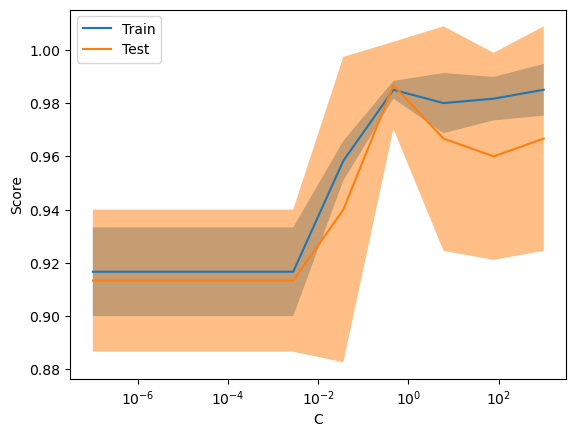

In [29]:
from sklearn.datasets import load_iris
from sklearn.model_selection import ValidationCurveDisplay
from sklearn.svm import SVC
from sklearn.utils import shuffle
X, y = load_iris(return_X_y=True)
X, y = shuffle(X, y, random_state=0)
ValidationCurveDisplay.from_estimator(
   SVC(kernel="linear"), X, y, param_name="C", param_range=np.logspace(-7, 3, 10)
)

- If the training score and the validation score are both low, the estimator will be underfitting. 
- If the training score is high and the validation score is low, the estimator is overfitting and otherwise it is working very well. 
- A low training score and a high validation score is usually not possible.